# V4 · Modelado con la métrica del negocio

**Qué cambió desde la defensa de la Entrega 3.** El docente nos marcó que el F1 no responde la pregunta del proyecto. El banco no quiere un equilibrio abstracto entre precision y recall: quiere **llamar sólo a quienes van a decir que sí**, sin que se escape casi ninguno, y que cada "sí" le cueste la menor cantidad de llamadas posible.

| Decisión | V2 (defensa) | V4 (este notebook) |
|---|---|---|
| Métrica | F1 con umbral elegido | **Precision con recall ≥ 0,95**, leída como **llamadas por cada sí = 1 / precision** |
| Piso | Dummy y siempre-yes | **Llamar a todos**: recall 1, precision = tasa de sí |
| Datos | 80 % viejo para entrenar, 20 % reciente reservado | **Llamadas desde junio de 2009**, partidas 80/20 por tiempo |

- **Por qué precision y recall separados.** Fijamos cuánto recall exigimos (que se escape como mucho 1 de cada 20 "sí") y, con eso fijo, buscamos el modelo que más sube la precision. Un F1 o un F-beta mezclaría las dos cosas en un número que no se lee en llamadas.
- **Por qué 0,95 y no 1.** Con recall = 1 el umbral queda en el puntaje del "sí" peor puntuado, que es un solo cliente. Ese umbral cambia mucho de un período a otro y en el test casi nunca se sostiene. Igual mostramos la curva completa entre 0,80 y 1,0.
- **Por qué sólo las llamadas desde junio de 2009.** La tasa de sí cambia muchísimo en el tiempo, y las llamadas recientes son las que se parecen al uso actual.
- **Aviso sobre el test.** Una versión anterior (V3) ya se midió sobre un test que contiene a este. Este test no es virgen: el modelo y el umbral se eligieron con validación cruzada, pero el número del test hay que leerlo sabiendo eso.
- **No tenemos el monto depositado**, así que el costo se mide en llamadas, no en pesos.

Para correrlo (también en Colab) tienen que estar en la misma carpeta `_bank_marketing_silver.csv`, `modelado_v3.py`, `modelado_v2_e2.py` y `transformadores.py`. Las versiones exactas están en `requirements_v3.txt`.

In [1]:
import platform, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import confusion_matrix, classification_report, make_scorer
from sklearn.inspection import permutation_importance
import joblib
from transformadores import COLUMNAS_ENTRADA
import modelado_v3 as m3
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
warnings.filterwarnings("ignore", message="Skipping features without any observed values.*", category=UserWarning)
print({"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
       "sklearn": sklearn.__version__, "seed": SEED, "recall_min": m3.RECALL_MIN})

{'python': '3.12.3', 'pandas': '3.1.0', 'numpy': '2.5.4', 'sklearn': '1.9.1', 'seed': 42, 'recall_min': 0.95}


## 1. Datos

Se deriva la fecha de cada contacto, se ordena por tiempo y se toman las llamadas desde junio de 2009. Esas filas se parten por tiempo: el 80 % más viejo es el entrenamiento, donde se hace la validación cruzada, y el 20 % más nuevo es el test, que se mira **una sola vez** al final.

In [2]:
archivo = Path("_bank_marketing_silver.csv")
print("SHA256 CSV:", hashlib.sha256(archivo.read_bytes()).hexdigest())
df = pd.read_csv(archivo).rename(columns={"contact": "contact_type", "y": "deposit_subscribed"})
meses = {m: i for i, m in enumerate("jan feb mar apr may jun jul aug sep oct nov dec".split(), 1)}
num_mes = df["month"].str.lower().map(meses)
assert num_mes.notna().all(), "Mes desconocido"
anios, anio, anterior = [], 2008, 4
for mes in num_mes:
    if mes < anterior:
        anio += 1
    anios.append(anio)
    anterior = mes
df["contact_date"] = pd.to_datetime(pd.DataFrame({"year": anios, "month": num_mes, "day": df["day"]}))
df = df.sort_values(["contact_date", "contact_id"], kind="stable").reset_index(drop=True)
assert df["deposit_subscribed"].isin(["yes", "no"]).all()
columnas = COLUMNAS_ENTRADA + ["previous"]
reciente = df[df.contact_date >= "2009-06-01"].reset_index(drop=True)
assert len(reciente) == 5459
corte2 = int(len(reciente) * 0.8)
X_tr, X_te = reciente.iloc[:corte2][columnas], reciente.iloc[corte2:][columnas]
y_tr = reciente.iloc[:corte2]["deposit_subscribed"].eq("yes").astype(int)
y_te = reciente.iloc[corte2:]["deposit_subscribed"].eq("yes").astype(int)
cortes = list(TimeSeriesSplit(n_splits=5).split(X_tr))

si = df["deposit_subscribed"].eq("yes")
display(pd.DataFrame([
    {"tramo": "dataset completo", "filas": len(df), "desde": df.contact_date.min().date(), "hasta": df.contact_date.max().date(), "tasa_si": si.mean()},
    {"tramo": "antes de junio 2009 (no se usa)", "filas": int((df.contact_date < "2009-06-01").sum()), "desde": df.contact_date.min().date(), "hasta": df.contact_date[df.contact_date < "2009-06-01"].max().date(), "tasa_si": si[df.contact_date < "2009-06-01"].mean()},
    {"tramo": "desde junio 2009 (se usa)", "filas": len(reciente), "desde": reciente.contact_date.iloc[0].date(), "hasta": reciente.contact_date.iloc[-1].date(), "tasa_si": reciente.deposit_subscribed.eq("yes").mean()},
    {"tramo": "  entrenamiento (80 %)", "filas": len(X_tr), "desde": reciente.contact_date.iloc[0].date(), "hasta": reciente.contact_date.iloc[corte2-1].date(), "tasa_si": y_tr.mean()},
]).assign(llamadas_por_si=lambda t: 1 / t.tasa_si).round(4))
print("Test reservado:", len(X_te), "filas, desde", reciente.contact_date.iloc[corte2].date(), "— su tasa de sí se mira recién en la sección 5.")
display(pd.DataFrame([{"fold": i, "n_entrena": len(tr), "n_valida": len(va),
    "valida_desde": reciente.contact_date.iloc[va[0]].date(), "valida_hasta": reciente.contact_date.iloc[va[-1]].date(),
    "tasa_si_valida": y_tr.iloc[va].mean()} for i, (tr, va) in enumerate(cortes, 1)]).round(3))

SHA256 CSV: f749e8bee883e1b98ba913fbdf26a91e25049b11a650940bdaef302e39a97e35


,tramo,filas,desde,hasta,tasa_si,llamadas_por_si
0,dataset completo,45211,2008-05-05,2010-11-17,0.1170,8.5481
1,antes de junio 2009 (no se usa),39752,2008-05-05,2009-05-28,0.0705,14.1819
2,desde junio 2009 (se usa),5459,2009-06-01,2010-11-17,0.4554,2.1959
3,entrenamiento (80 %),4367,2009-06-01,2010-07-09,0.4452,2.2464


Test reservado: 1092 filas, desde 2010-07-09 — su tasa de sí se mira recién en la sección 5.


,fold,n_entrena,n_valida,valida_desde,valida_hasta,tasa_si_valida
0,1,732,727,2009-07-07,2009-08-21,0.333
1,2,1459,727,2009-08-21,2009-10-22,0.389
2,3,2186,727,2009-10-22,2010-01-14,0.503
3,4,2913,727,2010-01-14,2010-04-01,0.517
4,5,3640,727,2010-04-01,2010-07-09,0.545


## 2. Cómo se lee la métrica

Para cada modelo y cada fold de validación:

1. El modelo ordena a los clientes del fold por probabilidad de decir que sí.
2. Se baja el umbral hasta conseguir al menos el 95 % de los "sí" del fold (recall ≥ 0,95) y se toma el umbral con mejor precision.
3. Se reporta la **precision** (tasa de sí entre los llamados) y las **llamadas por sí** (1 / precision).

**Aclaración honesta:** en la validación cruzada el umbral se elige mirando el mismo fold que se mide. Sirve para **comparar modelos entre sí** en igualdad de condiciones, pero es optimista. En el test el umbral se fija **antes** de mirar (sección 5).

**La tasa de sí cambia bastante entre el primer y el último fold** (ver la tabla de la sección 1). Por eso la precision promedio tiene un desvío enorme que no habla del modelo sino del período. Para comparar modelos usamos el **ahorro**: cuánto bajan las llamadas por sí respecto de llamar a todos en ese mismo fold (`1 − tasa_si / precision`). Dentro de cada fold, el ahorro ordena igual que la precision.

El **piso** es `DummyClassifier(strategy="prior")`: le da el mismo puntaje a todos, así que para tener recall ≥ 0,95 tiene que llamar a todos. Precision = tasa de sí, ahorro = 0.

## 3. Comparación de modelos

Las columnas son las del conjunto conservador de la Entrega 2 (`e2_deudas`): sin `duration` (fuga), y sin `campaign`, `contact`, `day` ni `month`, porque no está acreditado que se conozcan antes de la llamada. Todo va adentro del pipeline (derivar columnas → imputar → escalar / one-hot → modelo).

- **Logística**: C ∈ {0,1; 1; 10; 100} × `class_weight` ∈ {ninguno, balanced}. Es la referencia.
- **Árbol, bosque y boosting**: una configuración regularizada cada uno, con las mismas columnas y la misma validación.
- **Ablación**: la misma logística (C = 10) con las mismas columnas más `month` y `contact_type`, para mostrar el número con y sin esas dos columnas.

In [3]:
candidatos = [("piso", "e2_deudas", {})]
candidatos += [("logistica", "e2_deudas", dict(C=C, class_weight=w)) for C in (0.1, 1.0, 10.0, 100.0) for w in (None, "balanced")]
candidatos += [
    ("arbol", "e2_deudas", dict(max_depth=4, min_samples_leaf=50)),
    ("bosque", "e2_deudas", dict(max_depth=8, min_samples_leaf=20)),
    ("boosting", "e2_deudas", dict(learning_rate=0.05, max_iter=200, max_leaf_nodes=7, min_samples_leaf=50)),
    ("logistica", "e2_deudas_mes_contacto", dict(C=10.0, class_weight=None)),
]
tabla, por_fold = m3.buscar(candidatos, X_tr, y_tr, cortes)
print("Tabla completa, ordenada por ahorro medio (validación cruzada temporal, 5 folds):")
display(tabla.sort_values("ahorro_media", ascending=False).round(4))
print("Ahorro por fold (filas = fold, columnas = candidato):")
display(por_fold.pivot(index="fold", columns="candidato", values="ahorro_llamadas").round(4))
tabla.to_csv("v4_busqueda_completa.csv", index=False)
por_fold.to_csv("v4_por_fold.csv", index=False)

Tabla completa, ordenada por ahorro medio (validación cruzada temporal, 5 folds):


,candidato,familia,modo,params,precision_media,precision_desvio,ahorro_media,ahorro_desvio,llamadas_por_si_media,recall_media,umbral_fold5,ap_media
4,4,logistica,e2_deudas,"{'C': 1.0, 'class_weight': 'balanced'}",0.4787,0.0838,0.0448,0.0162,2.1628,0.9561,0.3545,0.5990
3,3,logistica,e2_deudas,"{'C': 1.0, 'class_weight': None}",0.4781,0.0842,0.0434,0.0157,2.1666,0.9570,0.2904,0.5984
12,12,logistica,e2_deudas_mes_contacto,"{'C': 10.0, 'class_weight': None}",0.4789,0.0884,0.0433,0.0156,2.1711,0.9555,0.2754,0.6040
6,6,logistica,e2_deudas,"{'C': 10.0, 'class_weight': 'balanced'}",0.4779,0.0845,0.0428,0.0157,2.1682,0.9530,0.3673,0.5983
5,5,logistica,e2_deudas,"{'C': 10.0, 'class_weight': None}",0.4779,0.0847,0.0426,0.0161,2.1688,0.9595,0.2878,0.5979
8,8,logistica,e2_deudas,"{'C': 100.0, 'class_weight': 'balanced'}",0.4777,0.0843,0.0426,0.0149,2.1684,0.9568,0.3522,0.5983
7,7,logistica,e2_deudas,"{'C': 100.0, 'class_weight': None}",0.4772,0.0850,0.0413,0.0150,2.1723,0.9589,0.2877,0.5978
1,1,logistica,e2_deudas,"{'C': 0.1, 'class_weight': None}",0.4756,0.0862,0.0372,0.0164,2.1833,0.9572,0.3092,0.5972
2,2,logistica,e2_deudas,"{'C': 0.1, 'class_weight': 'balanced'}",0.4755,0.0860,0.0371,0.0145,2.1833,0.9589,0.3766,0.5979
11,11,boosting,e2_deudas,"{'learning_rate': 0.05, 'max_iter': 200, 'max_...",0.4722,0.0834,0.0316,0.0133,2.1917,0.9523,0.2771,0.5874


Ahorro por fold (filas = fold, columnas = candidato):


candidato,0,1,2,3,4,5,6,7,8,9,10,11,12
fold,,,,,,,,,,,,,
1,0.0,0.0187,0.0215,0.0361,0.0403,0.0331,0.0345,0.0316,0.0361,0.0000,0.0101,0.0506,0.0200
2,0.0,0.0521,0.0491,0.0614,0.0623,0.0600,0.0594,0.0557,0.0579,0.0240,0.0197,0.0203,0.0550
3,0.0,0.0311,0.0313,0.0293,0.0306,0.0291,0.0307,0.0291,0.0307,0.0000,0.0293,0.0133,0.0376
4,0.0,0.0607,0.0590,0.0630,0.0653,0.0642,0.0639,0.0630,0.0628,0.0152,0.0523,0.0376,0.0653
5,0.0,0.0233,0.0247,0.0269,0.0255,0.0269,0.0256,0.0269,0.0255,0.0247,0.0138,0.0363,0.0385


### Elección

Regla de parsimonia de la consigna: se toma el candidato con mayor ahorro medio, salvo que sea más complejo que la mejor logística y le gane por menos que el desvío de la logística. En ese caso se queda la logística. La ablación con `month` y `contact_type` **no compite**: incluye columnas que la Entrega 2 descartó por posible fuga, así que sólo se informa como evidencia.

In [4]:
elegible = tabla[tabla.modo.eq("e2_deudas")]
eleccion = m3.elegir(elegible)
familia, modo, params = candidatos[int(eleccion.candidato)]
display(eleccion.to_frame().T)
print("Modelo elegido:", familia, modo, params)
ref = elegible[elegible.familia.ne("piso")].sort_values("ahorro_media", ascending=False)
print("Diferencia con el segundo:", round(ref.ahorro_media.iloc[0] - ref.ahorro_media.iloc[1], 5))
abl = tabla[tabla.modo.eq("e2_deudas_mes_contacto")].iloc[0]
print(f"Ablación con month y contact_type: ahorro {abl.ahorro_media:.4f} ± {abl.ahorro_desvio:.4f} contra {eleccion.ahorro_media:.4f} ± {eleccion.ahorro_desvio:.4f} sin ellas.")
display(por_fold[por_fold.candidato.eq(int(eleccion.candidato))].round(4))

,candidato,familia,modo,params,precision_media,precision_desvio,ahorro_media,ahorro_desvio,llamadas_por_si_media,recall_media,umbral_fold5,ap_media
4,4,logistica,e2_deudas,"{'C': 1.0, 'class_weight': 'balanced'}",0.478718,0.083771,0.044794,0.016246,2.162773,0.95609,0.354462,0.598971


Modelo elegido: logistica e2_deudas {'C': 1.0, 'class_weight': 'balanced'}
Diferencia con el segundo: 0.00144
Ablación con month y contact_type: ahorro 0.0433 ± 0.0156 contra 0.0448 ± 0.0162 sin ellas.


,fold,tasa_si,precision,recall,umbral,llamadas_por_si,ahorro_llamadas,ap,candidato,familia,modo,params
20,1,0.3329,0.3468,0.9545,0.3108,2.8831,0.0403,0.4065,4,logistica,e2_deudas,"{'C': 1.0, 'class_weight': 'balanced'}"
21,2,0.3893,0.4151,0.9505,0.3570,2.4089,0.0623,0.5752,4,logistica,e2_deudas,"{'C': 1.0, 'class_weight': 'balanced'}"
22,3,0.5034,0.5193,0.9536,0.3479,1.9255,0.0306,0.6335,4,logistica,e2_deudas,"{'C': 1.0, 'class_weight': 'balanced'}"
23,4,0.5172,0.5533,0.9521,0.3752,1.8073,0.0653,0.6761,4,logistica,e2_deudas,"{'C': 1.0, 'class_weight': 'balanced'}"
24,5,0.5447,0.5590,0.9697,0.3545,1.7891,0.0255,0.7036,4,logistica,e2_deudas,"{'C': 1.0, 'class_weight': 'balanced'}"


## 4. Cuántos "sí" estamos dispuestos a perder

Esta tabla responde la pregunta del docente: **cuántas llamadas al pedo aceptamos con tal de que no se escape nadie**. Para el modelo elegido se repite la validación con distintos recall mínimos. Llamar a todos es la referencia: siempre consigue el 100 % de los sí.

Llamar a todos: 2.266 llamadas por sí en promedio de los folds; 1.836 en el fold 5.


,recall_min,si_perdidos_de_100,precision_media,llamadas_por_si_media,ahorro_media,ahorro_desvio,ahorro_fold5
0,0.80,17.9,0.5098,2.0386,0.1013,0.0196,0.1132
1,0.85,12.7,0.5020,2.0748,0.0865,0.0235,0.0900
2,0.90,8.5,0.4877,2.1276,0.0614,0.0125,0.0535
3,0.95,4.4,0.4787,2.1628,0.0448,0.0162,0.0255
4,1.00,0.0,0.4606,2.2510,0.0066,0.0042,0.0110


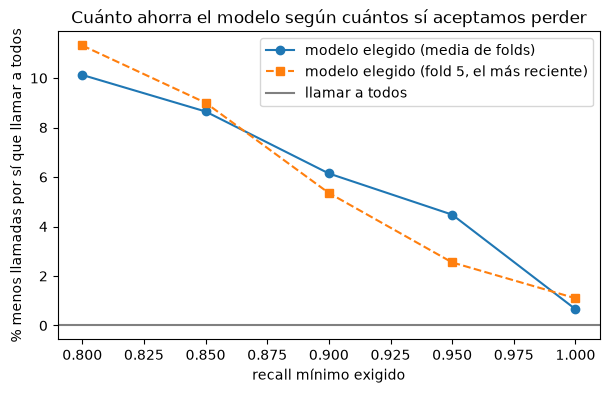

In [5]:
curva = []
for r in (0.80, 0.85, 0.90, 0.95, 1.00):
    d = m3.evaluar(familia, modo, params, X_tr, y_tr, cortes, recall_min=r)
    curva.append({"recall_min": r, "si_perdidos_de_100": round(100 * (1 - d.recall.mean()), 1),
                  "precision_media": d.precision.mean(), "llamadas_por_si_media": d.llamadas_por_si.mean(),
                  "ahorro_media": d.ahorro_llamadas.mean(), "ahorro_desvio": d.ahorro_llamadas.std(ddof=0),
                  "ahorro_fold5": d.ahorro_llamadas.iloc[-1]})
curva = pd.DataFrame(curva)
piso = por_fold[por_fold.familia.eq("piso")]
print(f"Llamar a todos: {piso.llamadas_por_si.mean():.3f} llamadas por sí en promedio de los folds; {piso.llamadas_por_si.iloc[-1]:.3f} en el fold 5.")
display(curva.round(4))
curva.to_csv("v4_curva_recall.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curva.recall_min, 100 * curva.ahorro_media, marker="o", label="modelo elegido (media de folds)")
ax.plot(curva.recall_min, 100 * curva.ahorro_fold5, marker="s", linestyle="--", label="modelo elegido (fold 5, el más reciente)")
ax.axhline(0, color="gray", label="llamar a todos")
ax.set_xlabel("recall mínimo exigido")
ax.set_ylabel("% menos llamadas por sí que llamar a todos")
ax.set_title("Cuánto ahorra el modelo según cuántos sí aceptamos perder")
ax.legend()
plt.show()

## 5. Test: una sola vez

El umbral se fija **antes** de mirar el test: es el umbral que logró recall ≥ 0,95 en el **fold 5**, el período más reciente del entrenamiento y el que más se parece al test. Así se imita el uso: se calibra con lo último que se vio. Después el modelo se entrena con todo el entrenamiento y se aplica una sola vez al test. El recall que salga se informa tal como sale, aunque no sea 0,95.

In [6]:
umbral = float(eleccion.umbral_fold5)
final = m3.construir(familia, modo, **params).fit(X_tr, y_tr)
p_te = final.predict_proba(X_te)[:, 1]
yt = y_te.to_numpy()
resultado = pd.DataFrame([
    {"estrategia": "llamar a todos", **m3.medir(yt, p_te, -np.inf)},
    {"estrategia": f"modelo, umbral {umbral:.4f}", **m3.medir(yt, p_te, umbral)},
]).set_index("estrategia")
resultado["llamadas_ahorradas"] = resultado.llamadas.iloc[0] - resultado.llamadas
resultado["si_perdidos"] = resultado.si_totales - resultado.si_conseguidos
resultado["ahorro_llamadas_por_si"] = 1 - resultado.llamadas_por_si / resultado.llamadas_por_si.iloc[0]
display(resultado.round(4))
pred = (p_te >= umbral).astype(int)
cm = confusion_matrix(yt, pred)
etiquetas = dict(index=["real no", "real sí"], columns=["no llamar", "llamar"])
print("Matriz de confusión (cantidades):"); display(pd.DataFrame(cm, **etiquetas))
print("Normalizada por fila (de cada clase real, qué hizo el modelo):"); display(pd.DataFrame(cm / cm.sum(1, keepdims=True), **etiquetas).round(3))
print("Normalizada por columna (de cada decisión, qué había):"); display(pd.DataFrame(cm / cm.sum(0, keepdims=True), **etiquetas).round(3))
print(classification_report(yt, pred, target_names=["no", "sí"], digits=3))
resultado.to_csv("v4_test.csv")

,llamadas,si_conseguidos,si_totales,precision,recall,llamadas_por_si,llamadas_ahorradas,si_perdidos,ahorro_llamadas_por_si
estrategia,,,,,,,,,
llamar a todos,1092,542,542,0.4963,1.0000,2.0148,0,0,0.0000
"modelo, umbral 0.3545",1003,519,542,0.5174,0.9576,1.9326,89,23,0.0408


Matriz de confusión (cantidades):


,no llamar,llamar
real no,66,484
real sí,23,519


Normalizada por fila (de cada clase real, qué hizo el modelo):


,no llamar,llamar
real no,0.120,0.880
real sí,0.042,0.958


Normalizada por columna (de cada decisión, qué había):


,no llamar,llamar
real no,0.742,0.483
real sí,0.258,0.517


              precision    recall  f1-score   support

          no      0.742     0.120     0.207       550
          sí      0.517     0.958     0.672       542

    accuracy                          0.536      1092
   macro avg      0.630     0.539     0.439      1092
weighted avg      0.630     0.536     0.438      1092



## 6. En qué se apoya el modelo

Importancia por permutación sobre el test: cuánto empeora el ordenamiento (average precision) al mezclar cada columna de entrada. Se muestran sólo las columnas que el pipeline usa.

In [7]:
imp = permutation_importance(final, X_te, y_te, scoring="average_precision", n_repeats=20, random_state=SEED)
importancia = pd.DataFrame({"columna": X_te.columns, "media": imp.importances_mean, "desvio": imp.importances_std})
importancia = importancia[importancia.media.abs() > 1e-9].sort_values("media", ascending=False)
display(importancia.round(4))
modelo = final.named_steps["modelo"]
if hasattr(modelo, "coef_"):
    nombres = final.named_steps["preparar"].get_feature_names_out()
    coef = pd.Series(modelo.coef_[0], index=nombres).sort_values(key=abs, ascending=False)
    print("Coeficientes de la logística (escala estandarizada), los 12 de mayor módulo:")
    display(coef.head(12).round(3).to_frame("coeficiente"))
joblib.dump(final, "modelo_final_v4.joblib")
print("Guardado modelo_final_v4.joblib. Umbral:", round(umbral, 6))

,columna,media,desvio
13,poutcome,0.1726,0.0121
1,job,0.0052,0.0084
7,loan,0.0027,0.0028
14,previous,0.0020,0.0068
12,pdays,0.0010,0.0090
3,education,0.0010,0.0021
6,housing,0.0010,0.0032
0,age,-0.0003,0.0013
5,balance,-0.0008,0.0023


Coeficientes de la logística (escala estandarizada), los 12 de mayor módulo:


,coeficiente
cat__poutcome_limpio_success,0.915
cat__poutcome_limpio_failure,-0.677
cat__job_desconocido,-0.650
cat__job_services,0.451
cat__loan_yes,-0.439
cat__poutcome_limpio_other,-0.373
cat__job_entrepreneur,-0.320
cat__job_blue-collar,0.318
cat__loan_no,0.280
cat__job_housemaid,-0.262


Guardado modelo_final_v4.joblib. Umbral: 0.354462


## Conclusión

**El resultado en el test (1.092 llamadas, de julio a noviembre de 2010):**

| | Llamadas | Sí conseguidos | Tasa de sí (precision) | Llamadas por sí | Ahorro por sí |
|---|---|---|---|---|---|
| Llamar a todos | 1.092 | 542 de 542 | 49,6 % | 2,01 | — |
| **Modelo** | 1.003 | 519 de 542 (recall 0,958) | 51,7 % | **1,93** | **4,1 %** |

- **Con el modelo, cada sí cuesta 4,1 % menos llamadas (1,93 contra 2,01).** En total son 89 llamadas menos (−8,2 %) a cambio de perder 23 de los 542 sí (−4,2 %). El recall exigido se sostuvo: 0,958 contra el mínimo de 0,95.
- **La validación lo anticipó.** El ahorro medio en validación fue 4,5 % y el test dio 4,1 %.
- **Por qué este modelo.** La logística con C = 1 y `class_weight="balanced"` tiene el mayor ahorro medio (4,5 % ± 1,6 %). Las otras logísticas quedan a menos de 0,2 puntos: el resultado no depende de afinar C. El boosting (3,2 %), el bosque (2,5 %) y el árbol (1,3 %) quedan por debajo, así que se queda la simple.
- **Desbalance.** La tasa de sí del entrenamiento es 44,5 %: ya casi no hay desbalance. `balanced` gana por 0,1 punto, una diferencia que no significa nada.
- **Lo que probamos y no sirvió.** Agregar `month` y `contact_type` no mejora (4,3 % contra 4,5 %). Además, la Entrega 2 las descartó por posible fuga, así que no entran.
- **En qué se apoya.** `poutcome`, el resultado de la campaña anterior, explica casi todo: haber dicho que sí antes es el coeficiente más alto (+0,92). No es fuga, porque se conoce antes de llamar. El resto de las columnas aporta muy poco.
- **El costo de cada punto de recall (sección 4).** Aceptando perder 18 de cada 100 sí (recall 0,80), el ahorro sube a 10 %. La decisión de dónde pararse es de negocio: conviene bajar el recall sólo si un sí vale menos que las llamadas que se ahorran.
- **Aviso honesto.** Este test está contenido en el test que ya miramos en V3, así que no es virgen. El modelo y el umbral se eligieron con validación cruzada, sin mirar el test.
- **Lo que no apareció.** Un modelo que baje mucho más el costo sin perder clientes. Con las columnas que se conocen antes de llamar, el techo está alrededor del 4–5 % de ahorro con recall 0,95.
